In [1]:
import sys, os, warnings, subprocess
subprocess.run(["pip", "install", ".", "--quiet"], check=True, cwd="/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales")
warnings.simplefilter("ignore", UserWarning)

import numpy as np
import scipy as sp
import pandas as pd
from tqdm import tqdm

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])

from src.plotting import plot_repeated_measures_violins, plot_subject_level_violins
from src.notebook import load_notebook_data
from src.timescales import create_ints_dataframe_custom_grouping, convert_data_dict, average_data_dict_converted
from snaplab_tools.plotting.plotting import plot_correlation_unity
from snaplab_tools.plotting.utils import get_my_colors
from snaplab_tools.utils import winsorize

  DEPRECATION: Building 'src' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'src'. Discussion can be found at https://github.com/pypa/pip/issues/6334


In [2]:
%matplotlib inline
plt.rcParams.update({
    'font.size':            8,
    'figure.dpi':           300,
    'svg.fonttype':         "none",
    'font.family':          'sans-serif',
    'font.sans-serif':      ['Roboto'],
    'axes.spines.top':      True,
    'axes.spines.right':    True
})

nas_scratch_dir = f'/mnt/lindenmp_nas/lindenmp/work/figure_scratch/intrinsic_neural_timescales'
if not os.path.exists(nas_scratch_dir):
    os.mkdir(nas_scratch_dir)

In [3]:
my_colors = get_my_colors(cat_trio=False, as_list=True)

def function_helper(data_dict_centiles):
    df_plot = pd.DataFrame()
    for c, condition in enumerate(data_dict_centiles.keys()):
        df_tmp_1 = pd.DataFrame()
        n_subs_tmp = data_dict_centiles[condition].shape[0]
        for i in np.arange(n_subs_tmp):
            df_tmp_2 = pd.DataFrame()
            df_tmp_2['subject'] = np.zeros(10) + i
            df_tmp_2[condition] = data_dict_centiles[condition][i, :]
            df_tmp_1 = pd.concat((df_tmp_1, df_tmp_2), axis=0)
        if c == 0:
            df_plot['subject'] = df_tmp_1['subject']
        df_plot[condition] = df_tmp_1[condition]
    return df_plot

# Maps raw condition keys -> display labels
LABEL_MAP = {
    'rest':             'Rest',
    'reversallearning': 'RL task',
    'frac2back':        '2-back',
    'nback':            'n-back',
    'task-Rest':        'Rest',
    'task-Movies':      'Movies',
    'task-Tasks':       'Tasks',
}

# Per-dataset loading configuration
DATASET_CONFIGS = {
    'HCP-YA': {
        'which_modality': 'FMRI',
        'use_7t':         True,
        'use_resids':     True,
        'output_type':    'timescale_auc_zero_crossing_bp-0.01-0.08hz',
        # 'output_type':    'timescale_auc_zero_crossing',
        'is_hcp':         True,
        'custom_order':   ['task-Rest', 'task-Movies', 'task-Tasks'],
        'title':          'HCP-YA',
    },
    'WAND': {
        'which_modality': 'FMRI',
        'use_7t':         False,
        'use_resids':     False,
        'output_type':    'timescale_auc_zero_crossing',
        'is_hcp':         False,
        'custom_order':   None,
        'title':          'WAND',
    },
    'HCP-D': {
        'which_modality': 'FMRI',
        'use_7t':         False,
        'use_resids':     True,
        'output_type':    'timescale_auc_zero_crossing_bp-0.01-0.08hz',
        'is_hcp':         True,
        'custom_order':   None,
        'title':          'HCP-D',
    },
    'PNC': {
        'which_modality': 'FMRI',
        'use_7t':         False,
        'use_resids':     True,
        'output_type':    'timescale_auc_zero_crossing',
        'is_hcp':         False,
        'custom_order':   None,
        'title':          'PNC',
    },
    'Penn_LEAD': {
        'which_modality': 'FMRI',
        'use_7t':         False,
        'use_resids':     True,
        'output_type':    'timescale_auc_zero_crossing',
        'is_hcp':         False,
        'custom_order':   None,
        'title':          'Penn LEAD',
    },
}

In [4]:
brain_map = 'SA_Axis'
all_data = {}

for dataset, cfg in DATASET_CONFIGS.items():
    print(f'\n=== Loading {dataset} ===')

    notebook_data = load_notebook_data(
        dataset=dataset,
        which_modality=cfg['which_modality'],
        use_7t=cfg['use_7t'],
        output_type=cfg['output_type'],
        use_resids=cfg['use_resids'],
        load_subject_data=False,
    )

    timescales_processor = notebook_data['timescales_processor']
    data_dict = notebook_data['data_dict']
    df_neuro  = notebook_data['supporting_data']['df_neuro']

    # --- df_ints: regional mean INTs per condition ---
    if cfg['is_hcp']:
        df_ints = create_ints_dataframe_custom_grouping(
            data_dict, sort_by_median=False,
            average_all_rest=True, average_7t_movies=True, average_3t_tasks=True,
        )
        if cfg['custom_order']:
            df_ints = df_ints[cfg['custom_order']]
    else:
        df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=True)

    # --- data_dict_centiles: subject × SA-centile arrays per condition ---
    data_dict_centiles = convert_data_dict(
        data_dict, timescales_processor.scan_registry,
        brain_map=df_neuro[brain_map], verbose=False,
    )

    if cfg['is_hcp']:
        data_dict_centiles = average_data_dict_converted(
            data_dict_centiles,
            average_all_rest=True, average_7t_movies=True, average_3t_tasks=True,
        )
        if cfg['custom_order']:
            data_dict_centiles = {
                k: data_dict_centiles[k]
                for k in cfg['custom_order']
                if k in data_dict_centiles
            }

    all_data[dataset] = {
        'df_ints':            df_ints,
        'df_neuro':           df_neuro,
        'data_dict_centiles': data_dict_centiles,
        'cfg':                cfg,
    }

    # For HCP-YA supplementary figure: store per-region converted data and subject IDs
    if dataset == 'HCP-YA':
        subject_ids_tmp = list(dict.fromkeys(scan.subject_id for scan in timescales_processor.scan_registry))
        data_dict_conv = convert_data_dict(
            data_dict, timescales_processor.scan_registry, verbose=False,
        )
        data_dict_conv = average_data_dict_converted(
            data_dict_conv, average_all_rest=True, average_7t_movies=True, average_3t_tasks=True,
        )
        if cfg['custom_order']:
            data_dict_conv = {k: data_dict_conv[k] for k in cfg['custom_order'] if k in data_dict_conv}
        all_data[dataset]['data_dict_converted'] = data_dict_conv
        all_data[dataset]['subject_ids'] = subject_ids_tmp

    print(f'  df_ints columns: {df_ints.columns.tolist()}')
    print(f'  centiles keys:   {list(data_dict_centiles.keys())}')


=== Loading HCP-YA ===
Loading data for notebooks...
Initialized DataLoader for dataset: HCP-YA
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded 3912 scans from scan_registry_HCP-YA_multi.csv


Loading metric_tsnr: 100%|██████████| 3912/3912 [00:00<00:00, 7597.25it/s]


3912
timescale_auc_zero_crossing_bp-0.01-0.08hz


Loading timescale_auc_zero_crossing_bp-0.01-0.08hz: 100%|██████████| 3912/3912 [00:00<00:00, 8475.38it/s]


3912


...

172
timescale_auc_zero_crossing


Loading timescale_auc_zero_crossing: 100%|██████████| 172/172 [00:00<00:00, 7620.13it/s]


172


Loading timescale_auc_zero_crossing_resids: 100%|██████████| 172/172 [00:00<00:00, 7718.45it/s]

172
Number of subjects: 43
  df_ints columns: ['rest', 'nback']
  centiles keys:   ['rest', 'nback']


Data shape: (400, 3)
Conditions: ['Rest', 'Movies', 'Tasks']
Number of subjects: 163
Selected regions: [0 1 2 3 4 5 6 7 8 9]
Conditions: ['Rest', 'Movies', 'Tasks']
Filtered data shape: (1630, 5)
Expected rows: 1630
Fitting polynomial trends to distribution means...
  Rest: Best fit = Quadratic (R² = 0.858)
  Movies: Best fit = Quadratic (R² = 0.645)
  Tasks: Best fit = Quadratic (R² = 0.841)
Data shape: (400, 2)
Conditions: ['Rest', 'RL task']
Number of subjects: 160
Selected regions: [0 1 2 3 4 5 6 7 8 9]
Conditions: ['Rest', 'RL task']
Filtered data shape: (1600, 4)
Expected rows: 1600
Fitting polynomial trends to distribution means...
  Rest: Best fit = Quadratic (R² = 0.767)
  RL task: Best fit = Quadratic (R² = 0.827)
Data shape: (400, 2)
Conditions: ['Rest', 'Tasks']
Number of subjects: 552
Selected regions: [0 1 2 3 4 5 6 7 8 9]
Conditions: ['Rest', 'Tasks']
Filtered data shape: (5520, 4)
Expected rows: 5520
Fitting polynomial trends to distribution means...
  Rest: Best fit = 

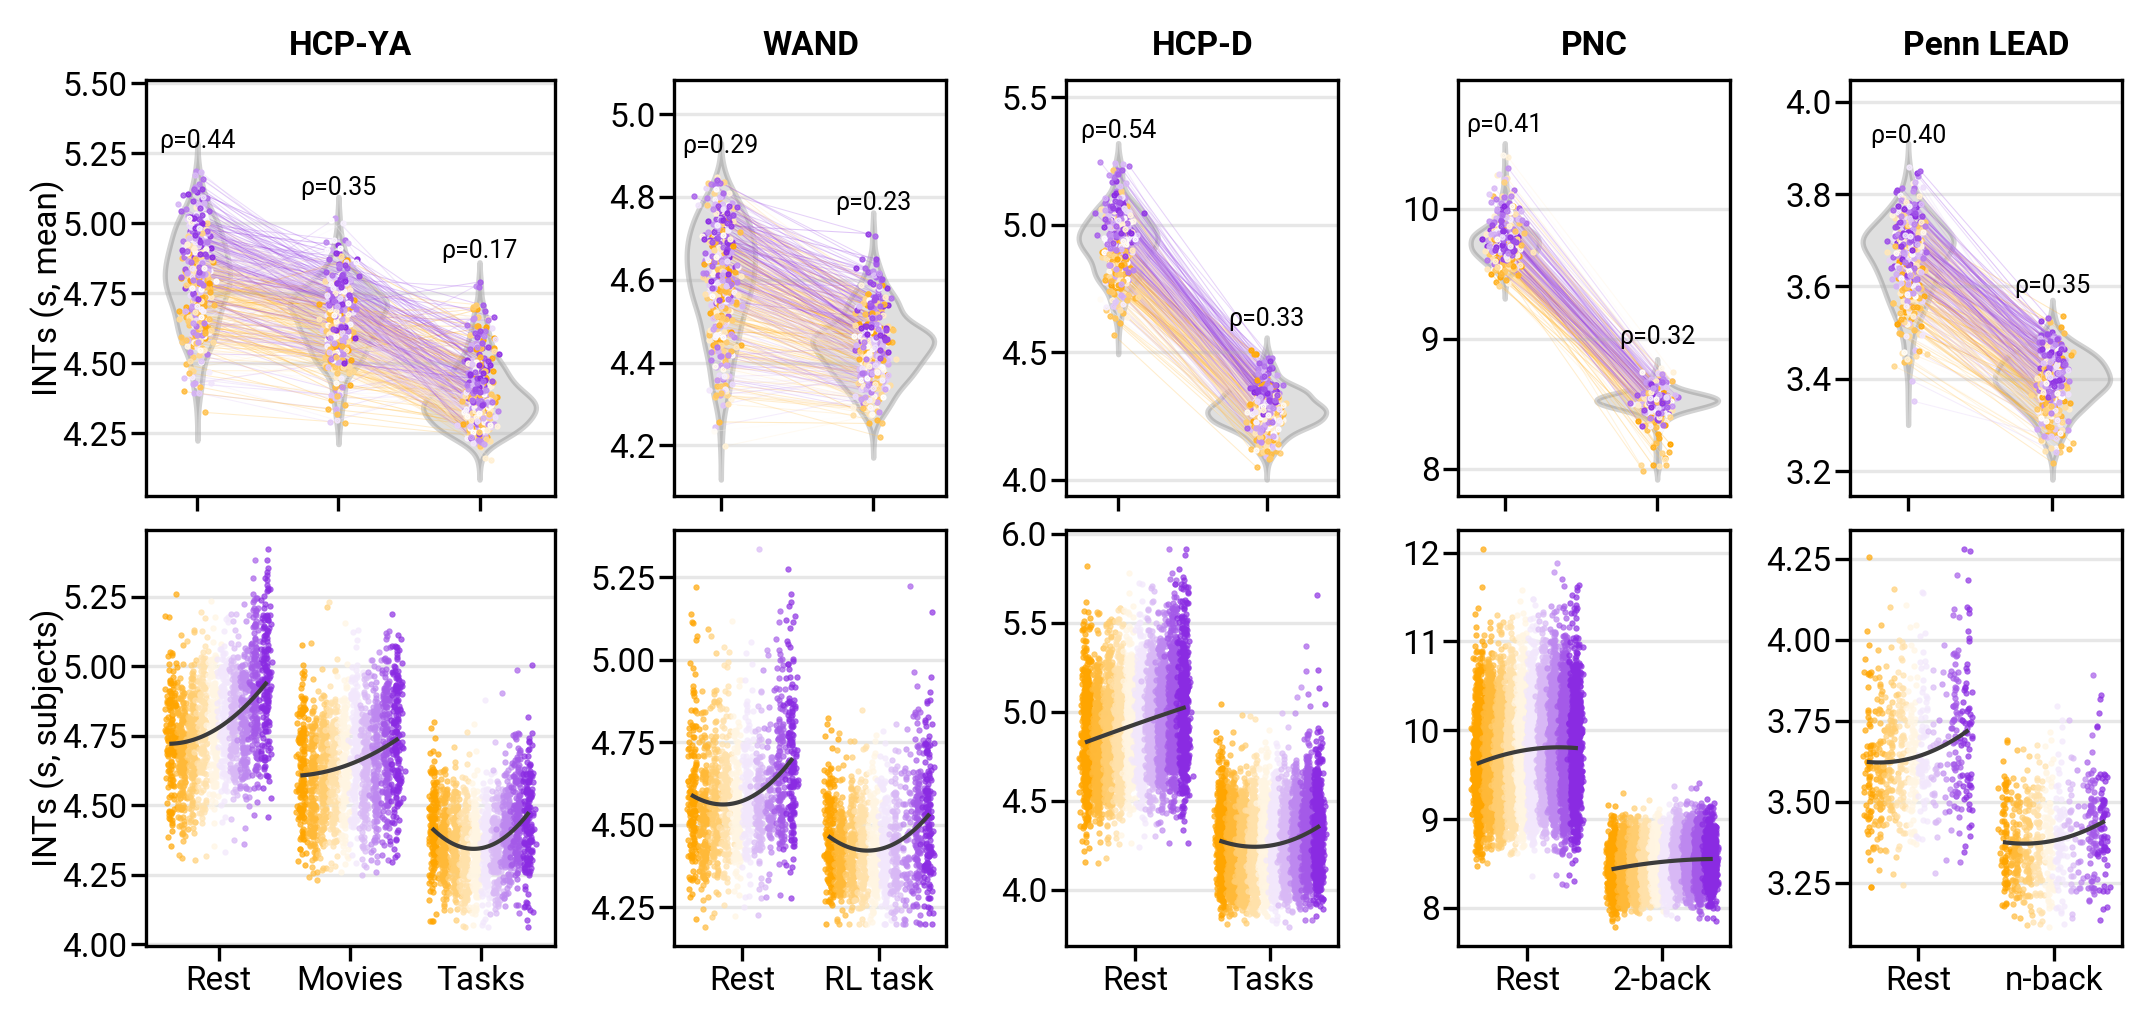

In [5]:
dataset_order = list(all_data.keys())
col_widths    = [len(all_data[d]['df_ints'].columns) for d in dataset_order]
total_conds   = sum(col_widths)

fig = plt.figure(figsize=(8.5, 3.75), dpi=300)
gs  = gridspec.GridSpec(
    2, len(dataset_order),
    width_ratios=col_widths,
    hspace=0.08, wspace=0.4,
)

ax0_first = ax1_first = None

for col_idx, dataset in enumerate(dataset_order):
    d   = all_data[dataset]
    cfg = d['cfg']
    is_first_col = (col_idx == 0)

    df_ints            = d['df_ints'].copy()
    df_neuro           = d['df_neuro']
    data_dict_centiles = d['data_dict_centiles']

    ax0 = fig.add_subplot(gs[0, col_idx])
    ax1 = fig.add_subplot(gs[1, col_idx])
    if is_first_col:
        ax0_first, ax1_first = ax0, ax1

    # Build centile df and apply WAND-specific winsorize
    df_centiles = function_helper(data_dict_centiles)
    if dataset == 'WAND' and 'reversallearning' in df_centiles.columns:
        df_centiles['reversallearning'] = winsorize(df_centiles['reversallearning'])

    # Rename columns to display labels
    df_ints     = df_ints.rename(columns=LABEL_MAP)
    df_centiles = df_centiles.rename(columns=LABEL_MAP)

    # Align centile column order to match df_ints
    cond_cols = [c for c in df_centiles.columns if c != 'subject']
    ordered   = [c for c in df_ints.columns if c in cond_cols]
    df_centiles = df_centiles[['subject'] + ordered]

    # --- Row A: regional mean violins ---
    ax0 = plot_repeated_measures_violins(
        df_ints, ax0,
        color_vector=df_neuro[brain_map], colormap='sydnor_sa',
        add_colorbar=False,
        point_alpha=1, line_alpha=0.3, point_size=0.25, line_width=0.25,
        violin_alpha=0.25, correlation_method='spearman', annotate_variance=False,
    )
    ax0.set_xticklabels([])
    ax0.set_xlabel('')
    ax0.set_title(cfg['title'], fontsize=8, fontweight='bold')

    # --- Row B: subject-level centile scatter ---
    ax1, _ = plot_subject_level_violins(
        df_centiles, ax1, np.arange(10),
        point_alpha=0.75, point_size=0.25,
        show_violins=False, show_lines=False, fit_trends=True,
        show_r2_annotation=False, annotate_variance=False,
        hide_legend=True, sort_by_median=False,
    )
    ax1.set_xlabel('')

    # y-labels only on leftmost column
    if is_first_col:
        ax0.set_ylabel('INTs (s, mean)',     fontsize=8)
        ax1.set_ylabel('INTs (s, subjects)', fontsize=8)
    else:
        ax0.set_ylabel('')
        ax1.set_ylabel('')

    for ax in [ax0, ax1]:
        ax.tick_params(axis='y', which='major', pad=1)
        ax.tick_params(axis='x', which='major', pad=1)
        ax.yaxis.set_label_coords(-0.2, 0.5)

# Panel labels (placed after tight_layout so positions are final)
plt.tight_layout()
ax0_pos = ax0_first.get_position()
ax1_pos = ax1_first.get_position()
# fig.text(0.005, ax0_pos.y1 + 0.01, 'A', fontsize=10, fontweight='bold', va='bottom')
# fig.text(0.005, ax1_pos.y1 + 0.01, 'B', fontsize=10, fontweight='bold', va='bottom')

fig.savefig(
    os.path.join(nas_scratch_dir, 'timescales_analysis_fig1.png'),
    bbox_inches='tight', dpi=1000, transparent=True,
)
plt.show()

In [6]:
# Compute per-subject SA-axis Pearson correlation for HCP-YA supplementary figure
hcpya = all_data['HCP-YA']
subject_ids_hcpya  = hcpya['subject_ids']
data_dict_conv     = hcpya['data_dict_converted']
df_neuro_hcpya     = hcpya['df_neuro']
n_subs_hcpya       = len(subject_ids_hcpya)

df_corr = pd.DataFrame(index=subject_ids_hcpya)
df_corr.index.name = 'subject_ids'
for int_col in data_dict_conv.keys():
    for i in tqdm(np.arange(n_subs_hcpya), desc=int_col):
        subject_id = subject_ids_hcpya[i]
        nan_mask = np.isnan(data_dict_conv[int_col][i])
        corr = sp.stats.pearsonr(
            data_dict_conv[int_col][i][~nan_mask],
            df_neuro_hcpya[brain_map][~nan_mask],
        )
        df_corr.loc[subject_id, int_col] = corr[0]

df_corr.head()

task-Tasks: 100%|██████████| 163/163 [00:00<00:00, 4859.25it/s]


,task-Rest,task-Movies,task-Tasks
subject_ids,,,
100610,0.421806,0.325566,0.221131
102311,0.356349,0.074466,0.038720
102816,0.254557,0.274918,0.008150
104416,-0.031376,-0.063898,0.167560
105923,0.399506,0.239551,0.217225


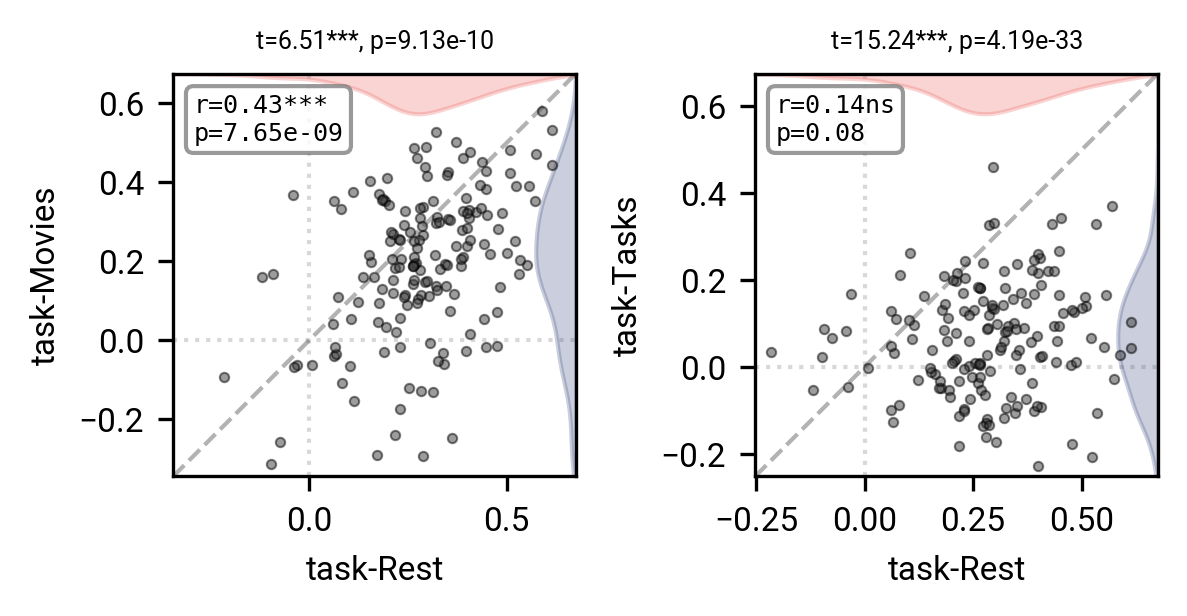

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=2, sharex=False, sharey=False, figsize=(4, 2), dpi=300)
plot_correlation_unity(df_corr['task-Rest'], df_corr['task-Movies'], axes[0],
                       marginal_color_x=my_colors[0], marginal_color_y=my_colors[1],
                       show_marginals=True, show_correlation=True, correlation_type='pearson', grid=False, size=5, fontsize=8)
plot_correlation_unity(df_corr['task-Rest'], df_corr['task-Tasks'], axes[1],
                       marginal_color_x=my_colors[0], marginal_color_y=my_colors[1],
                       show_marginals=True, show_correlation=True, correlation_type='pearson', grid=False, size=5, fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, 'neuroanatomy_INTs_correlations_unity.svg'), bbox_inches='tight', dpi=1000, transparent=True)
plt.show()